# Experimental Characterization of LoRa Propagation and Machine Learning-Based Path Loss Modeling Across Diverse Hill Terrains in Nepal
Peter Karki · 17624929 · ST7072CEM Machine Learning

## 1. Setup

In [1]:
%pip install -q numpy pandas matplotlib scipy scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, glob, zipfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore')
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 30)

plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 9,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': '#e6e6e6', 'grid.linewidth': 0.6,
    'savefig.dpi': 300, 'savefig.bbox': 'tight', 'figure.dpi': 110})
W = 3.5
CASE = {'A': 1, 'B': 2, 'C': 3, 'D': 3}
COL  = {1: '#CC79A7', 2: '#0072B2', 3: '#D55E00'}
MK   = {1: 'o', 2: 's', 3: '^'}
NAME = {1: 'Case 1: forested slope', 2: 'Case 2: hill slope', 3: 'Case 3: town rooftops'}
FIG = 'figures'; os.makedirs(FIG, exist_ok=True)
rmse = lambda a, b: float(np.sqrt(np.mean((np.asarray(a) - np.asarray(b)) ** 2)))
RESULTS = {}

## 2. Load and combine the raw data

In [3]:
DATA = 'LoRa_data'
if not os.path.isdir(DATA) and os.path.exists('LoRa_data.zip'):
    zipfile.ZipFile('LoRa_data.zip').extractall('.')
files = sorted(glob.glob(os.path.join(DATA, 'raw', 'site_*_roamer_log.csv')))
print(files)
pd.read_csv(files[0]).head()

['LoRa_data/raw/site_A_roamer_log.csv', 'LoRa_data/raw/site_B_roamer_log.csv', 'LoRa_data/raw/site_C_roamer_log.csv', 'LoRa_data/raw/site_D_roamer_log.csv']


,row_id,uptime_ms,utc_time,session,stop_id,mode,sf,pwr,bw,pkt,tag,rssi,snr,lat,lon,gps_alt_m,mark,status,pos_src,phone_lat,phone_lon,phone_alt_m,phone_acc_m
0,NaN,NaN,NaN,SITE_A,1.0,MANUAL,NaN,NaN,NaN,NaN,NaN,NaN,NaN,27.766140,85.293246,NaN,NaN,NOACK,NaN,NaN,NaN,NaN,NaN
1,10.0,341093.0,2026-10-07T01:13:28Z,SITE_A,2.0,MANUAL,7.0,2.0,125.0,1.0,K2S7P2N1,NaN,NaN,27.766139,85.293242,1330.3,0.0,TIMEOUT,PHONE,27.766139,85.293242,1330.3,3.0
2,11.0,341290.0,2026-10-07T01:13:28Z,SITE_A,2.0,MANUAL,7.0,2.0,125.0,2.0,K2S7P2N2,NaN,NaN,27.766139,85.293242,1330.3,0.0,TIMEOUT,PHONE,27.766139,85.293242,1330.3,3.0
3,12.0,341487.0,2026-10-07T01:13:28Z,SITE_A,2.0,MANUAL,7.0,2.0,125.0,3.0,K2S7P2N3,NaN,NaN,27.766139,85.293242,1330.3,0.0,TIMEOUT,PHONE,27.766139,85.293242,1330.3,3.0
4,13.0,341684.0,2026-10-07T01:13:29Z,SITE_A,2.0,MANUAL,7.0,2.0,125.0,4.0,K2S7P2N4,NaN,NaN,27.766139,85.293242,1330.3,0.0,TIMEOUT,PHONE,27.766139,85.293242,1330.3,3.0


In [4]:
logs = []
for f in files:
    d = pd.read_csv(f)
    d['site'] = os.path.basename(f).split('_')[1]
    logs.append(d)
    print(f'{os.path.basename(f):26s} rows {len(d):5d}  ', d.status.value_counts().to_dict())
log = pd.concat(logs, ignore_index=True)
print('combined log:', log.shape)
log.groupby(['site', 'status']).size().unstack(fill_value=0)

site_A_roamer_log.csv      rows  1540   {'TIMEOUT': 967, 'OK': 563, 'NOACK': 10}
site_B_roamer_log.csv      rows  3262   {'OK': 1737, 'TIMEOUT': 1503, 'NOACK': 22}
site_C_roamer_log.csv      rows   376   {'OK': 197, 'TIMEOUT': 163, 'NOACK': 16}
site_D_roamer_log.csv      rows   368   {'TIMEOUT': 245, 'OK': 115, 'NOACK': 8}
combined log: (5546, 24)


status,NOACK,OK,TIMEOUT
site,,,
A,10,563,967
B,22,1737,1503
C,16,197,163
D,8,115,245


In [5]:
sweeps = log[log.status.isin(['OK', 'TIMEOUT'])].copy()
sweeps['stop_key'] = sweeps.site + sweeps.stop_id.astype(int).astype(str)
slots = sweeps.groupby('stop_key').size()
complete = slots[slots == 90].index
raw = sweeps[sweeps.stop_key.isin(complete)].drop(columns='stop_key').reset_index(drop=True)
print('stops logged:', len(slots), '| complete stops:', len(complete), '| incomplete dropped:', int((slots != 90).sum()))

fails = (log[log.status == 'NOACK'][['site', 'stop_id', 'lat', 'lon']]
         .rename(columns={'stop_id': 'attempt_id'}).sort_values(['site', 'attempt_id']).reset_index(drop=True))
feat = pd.read_csv(os.path.join(DATA, 'stop_features.csv'))
stations = pd.read_csv(os.path.join(DATA, 'stations.csv'))
print('raw sweeps:', raw.shape, '| failed handshakes:', fails.shape, '| stop features:', feat.shape, '| stations:', stations.shape)
feat.head()

stops logged: 61 | complete stops: 61 | incomplete dropped: 0
raw sweeps: (5490, 24) | failed handshakes: (56, 4) | stop features: (61, 12) | stations: (4, 3)


,stop_key,site,distance_to_station_m,station_ant_m,roamer_ant_m,stop_elev_m_srtm30,station_elev_m_srtm30,elev_diff_m,elev_angle_deg,terrain_category,land_cover,line_of_sight
0,A13,A,236.0,2.0,1.3,1397,1372,25,5.88,mountain,forest,blocked
1,A14,A,202.0,2.0,1.3,1403,1372,31,8.53,mountain,mixed,partly blocked
2,A15,A,201.0,2.0,1.3,1403,1372,31,8.57,mountain,mixed,clear
3,A16,A,182.0,2.0,1.3,1408,1372,36,10.98,mountain,forest,blocked
4,A18,A,229.0,2.0,1.3,1376,1372,4,0.83,mountain,mixed,partly blocked


## 3. Data checks

In [6]:
raw['stop_key'] = raw.site + raw.stop_id.astype(int).astype(str)
per_stop = raw.groupby('stop_key').size()
print('stops:', raw.stop_key.nunique(), '| every stop has 90 slots:', bool((per_stop == 90).all()))
print('slots:', len(raw), '| status counts:', raw.status.value_counts().to_dict())
print('received share: %.1f %%' % (100 * (raw.status == 'OK').mean()))
print('stops per site:', raw.groupby('site').stop_key.nunique().to_dict())
assert raw.stop_key.nunique() == 61 and (per_stop == 90).all() and len(raw) == 5490
assert set(raw.status.unique()) <= {'OK', 'TIMEOUT'}
assert raw.loc[raw.status == 'OK', 'rssi'].notna().all() and raw.loc[raw.status == 'TIMEOUT', 'rssi'].isna().all()
print('Cleaning checks passed: 61 complete stops, 5,490 slots, OK/TIMEOUT only, RSSI present exactly when OK.')

stops: 61 | every stop has 90 slots: True
slots: 5490 | status counts: {'TIMEOUT': 2878, 'OK': 2612}
received share: 47.6 %
stops per site: {'A': 17, 'B': 36, 'C': 4, 'D': 4}
Cleaning checks passed: 61 complete stops, 5,490 slots, OK/TIMEOUT only, RSSI present exactly when OK.


## 4. Features and targets

In [7]:
p = raw.copy()
p['ok'] = (p.status == 'OK').astype(int)
p['pl_db'] = np.where(p.ok == 1, p.pwr - p.rssi, np.nan)
p['case'] = p.site.map(CASE)
p = p.merge(feat.drop(columns='site'), on='stop_key', how='left')
p['logd'] = np.log10(p.distance_to_station_m)

s = p.groupby('stop_key').agg(site=('site', 'first'), n_ok=('ok', 'sum'),
        pl_median=('pl_db', 'median'), rssi_median=('rssi', 'median'), snr_median=('snr', 'median'),
        lat=('lat', 'median'), lon=('lon', 'median')).reset_index()
s = s.merge(p[p.pwr == 14].groupby('stop_key').pl_db.median().rename('pl_median_14dbm'), on='stop_key')
s['delivery_rate'] = s.n_ok / 90
s = s.merge(feat.drop(columns='site'), on='stop_key')
s['case'] = s.site.map(CASE); s['logd'] = np.log10(s.distance_to_station_m)
for c in ['built-up', 'mixed', 'open']:
    s['lc_' + c] = (s.land_cover == c).astype(int)
for c in ['lc_built-up', 'lc_mixed', 'lc_open']:
    p[c] = p.stop_key.map(s.set_index('stop_key')[c])
LC = ['lc_built-up', 'lc_mixed', 'lc_open']

print('stops with a 14 dBm path loss value:', s.pl_median_14dbm.notna().sum(), '(the missing one received nothing:',
      s[s.pl_median_14dbm.isna()].stop_key.tolist(), ')')
print('land cover counts:', s.land_cover.value_counts().to_dict())
s[['stop_key', 'case', 'distance_to_station_m', 'n_ok', 'delivery_rate', 'pl_median_14dbm', 'elev_diff_m', 'land_cover']].head(8)

stops with a 14 dBm path loss value: 60 (the missing one received nothing: ['A7'] )
land cover counts: {'mixed': 31, 'forest': 14, 'built-up': 12, 'open': 4}


,stop_key,case,distance_to_station_m,n_ok,delivery_rate,pl_median_14dbm,elev_diff_m,land_cover
0,A13,1,236.0,5,0.055556,141.5,25,forest
1,A14,1,202.0,12,0.133333,129.0,31,mixed
2,A15,1,201.0,59,0.655556,122.0,31,mixed
3,A16,1,182.0,2,0.022222,139.0,36,forest
4,A18,1,229.0,19,0.211111,135.0,4,mixed
5,A19,1,178.0,56,0.622222,124.0,9,built-up
6,A2,1,22.0,84,0.933333,108.0,5,built-up
7,A21,1,187.0,35,0.388889,123.0,0,open


## 5. Exploratory analysis
### Instrument check

noise floor: -117.0 dBm
 SF  weakest_RSSI  expected_sensitivity  lowest_SNR  SNR_limit
  7        -124.0                -124.5       -10.0       -7.5
  8        -128.0                -127.0       -14.0      -10.0
  9        -129.0                -129.5       -16.0      -12.5
 10        -131.0                -132.0       -18.0      -15.0
 11        -132.0                -134.5       -19.0      -17.5
 12        -134.0                -137.0       -21.0      -20.0

RSSI rise at same stop and SF (nominal 12, 6, 6 dB): {'2->14': np.float64(15.25), '8->14': np.float64(8.0), '2->8': np.float64(7.0)}


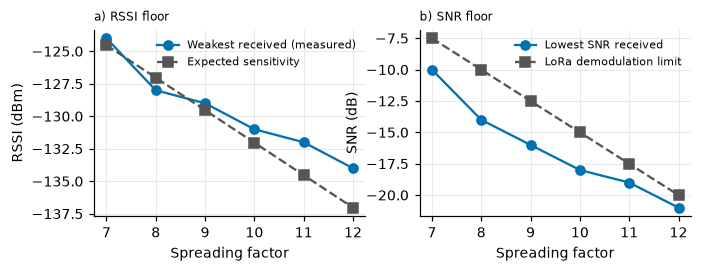

In [8]:
o = p[p.ok == 1]
sf = np.arange(7, 13)
snr_limit = np.array([-7.5, -10, -12.5, -15, -17.5, -20])
noise_floor = -174 + 10 * np.log10(125_000) + 6
sens = noise_floor + snr_limit
inst = pd.DataFrame({'SF': sf, 'weakest_RSSI': o.groupby('sf').rssi.min().values, 'expected_sensitivity': sens.round(1),
                     'lowest_SNR': o.groupby('sf').snr.min().values, 'SNR_limit': snr_limit})
print('noise floor: %.1f dBm' % noise_floor); print(inst.to_string(index=False))

t_ = o.groupby(['stop_key', 'sf', 'pwr']).rssi.median().unstack()
pw = {'2->14': (t_[14] - t_[2]).median(), '8->14': (t_[14] - t_[8]).median(), '2->8': (t_[8] - t_[2]).median()}
print('\nRSSI rise at same stop and SF (nominal 12, 6, 6 dB):', {k: round(v, 2) for k, v in pw.items()})
RESULTS.update(weakest_rssi_sf7=inst.weakest_RSSI[0], weakest_rssi_sf12=inst.weakest_RSSI[5], power_rise_2_14=pw['2->14'])

fig, axs = plt.subplots(1, 2, figsize=(W * 2, 2.2))
axs[0].plot(sf, inst.weakest_RSSI, 'o-', c='#0072B2', label='Weakest received (measured)')
axs[0].plot(sf, sens, 's--', c='#555', label='Expected sensitivity')
axs[1].plot(sf, inst.lowest_SNR, 'o-', c='#0072B2', label='Lowest SNR received')
axs[1].plot(sf, snr_limit, 's--', c='#555', label='LoRa demodulation limit')
for ax, yl, tt in zip(axs, ['RSSI (dBm)', 'SNR (dB)'], ['a) RSSI floor', 'b) SNR floor']):
    ax.set_xlabel('Spreading factor'); ax.set_ylabel(yl); ax.set_title(tt, fontsize=8, loc='left'); ax.legend(fontsize=7, frameon=False)
fig.savefig(f'{FIG}/fig7_sensitivity_check.png'); plt.show()

### Delivery by SF and power

All stops, delivery %:
pwr   2.0   8.0   14.0
sf                    
7.0   16.0  27.0  49.0
8.0   20.0  34.0  61.0
9.0   24.0  35.0  64.0
10.0  26.0  49.0  71.0
11.0  41.0  62.0  82.0
12.0  40.0  69.0  88.0


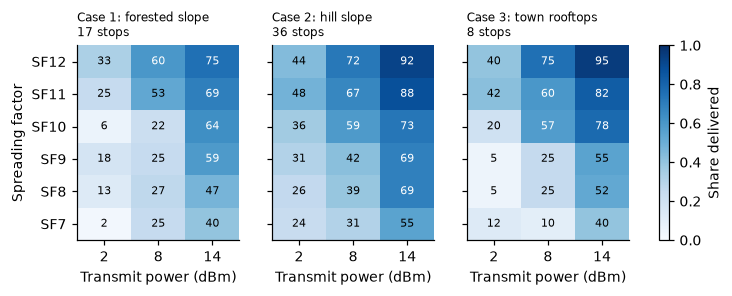

In [9]:
allt = p.pivot_table(index='sf', columns='pwr', values='ok', aggfunc='mean')
print('All stops, delivery %:'); print((allt * 100).round(0))
RESULTS.update(deliv_sf7_2=allt.loc[7, 2] * 100, deliv_sf12_14=allt.loc[12, 14] * 100)

fig, axs = plt.subplots(1, 3, figsize=(W * 2, 2.3), sharey=True)
for ax, c in zip(axs, (1, 2, 3)):
    tab = p[p.case == c].pivot_table(index='sf', columns='pwr', values='ok', aggfunc='mean')
    RESULTS[f'case{c}_sf12_14'] = tab.loc[12, 14] * 100; RESULTS[f'case{c}_sf7_2'] = tab.loc[7, 2] * 100
    im = ax.imshow(tab.values, cmap='Blues', vmin=0, vmax=1, origin='lower', aspect='auto'); ax.grid(False)
    for i in range(6):
        for j in range(3):
            v = tab.values[i, j]; ax.text(j, i, f'{v*100:.0f}', ha='center', va='center', fontsize=7, color='white' if v > .55 else 'black')
    ax.set_xticks(range(3)); ax.set_xticklabels(['2', '8', '14']); ax.set_xlabel('Transmit power (dBm)')
    ax.set_title(f'{NAME[c]}\n{p[p.case == c].stop_key.nunique()} stops', fontsize=8, loc='left')
axs[0].set_yticks(range(6)); axs[0].set_yticklabels([f'SF{i}' for i in range(7, 13)]); axs[0].set_ylabel('Spreading factor')
fig.colorbar(im, ax=axs, fraction=0.025).set_label('Share delivered')
fig.savefig(f'{FIG}/fig2_delivery_by_case.png'); plt.show()

### Delivery vs distance and elevation

    group  stops  rho_distance  p_distance  rho_elevdiff  p_elevdiff
All stops     61         0.054       0.679         0.335       0.008
   Case 1     17        -0.582       0.014        -0.257       0.319
   Case 2     36        -0.022       0.901         0.492       0.002
   Case 3      8        -0.422       0.298        -0.036       0.932


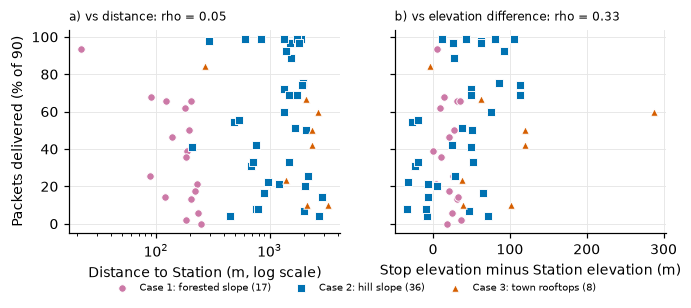

In [10]:
from scipy.stats import spearmanr

rows = []
for name, d in [('All stops', s)] + [(f'Case {c}', s[s.case == c]) for c in (1, 2, 3)]:
    r1 = spearmanr(d.distance_to_station_m, d.delivery_rate); r2 = spearmanr(d.elev_diff_m, d.delivery_rate)
    rows.append((name, len(d), r1[0], r1[1], r2[0], r2[1]))
corr = pd.DataFrame(rows, columns=['group', 'stops', 'rho_distance', 'p_distance', 'rho_elevdiff', 'p_elevdiff']).round(3)
print(corr.to_string(index=False))
RESULTS.update(rho_dist_all=corr.rho_distance[0], rho_elev_all=corr.rho_elevdiff[0], rho_dist_c1=corr.rho_distance[1], rho_elev_c2=corr.rho_elevdiff[2])

fig, axs = plt.subplots(1, 2, figsize=(W * 2, 2.4), sharey=True)
for c in (1, 2, 3):
    d = s[s.case == c]
    for ax, x in zip(axs, ['distance_to_station_m', 'elev_diff_m']):
        ax.scatter(d[x], d.delivery_rate * 100, s=24, c=COL[c], marker=MK[c], edgecolor='white', linewidth=.6, label=f'{NAME[c]} ({len(d)})', zorder=3)
axs[0].set_xscale('log'); axs[0].set_xlabel('Distance to Station (m, log scale)'); axs[1].set_xlabel('Stop elevation minus Station elevation (m)')
axs[0].set_ylabel('Packets delivered (% of 90)')
axs[0].set_title('a) vs distance: rho = 0.05', fontsize=8, loc='left'); axs[1].set_title('b) vs elevation difference: rho = 0.33', fontsize=8, loc='left')
axs[0].legend(fontsize=6.5, frameon=False, loc='upper center', bbox_to_anchor=(1.05, -0.2), ncol=3)
fig.savefig(f'{FIG}/fig3_delivery_vs_distance_elev.png'); plt.show()

## 6. Log-distance and Tobit fits

           stops     PL0     n  n_lo  n_hi    R2  sigma
All stops   60.0  124.49  0.14 -0.44  0.72  0.00  11.09
Case 1      16.0   84.26  2.10  0.65  3.56  0.41   6.75
Case 2      36.0  128.79 -0.07 -1.66  1.53  0.00  12.56
Case 3       8.0   88.00  1.41 -0.15  2.97  0.45   5.78


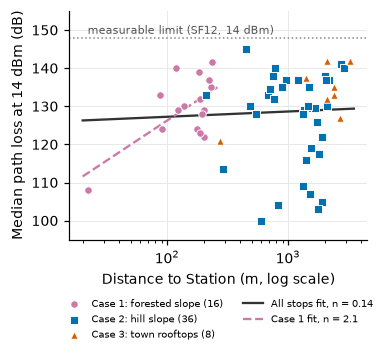

In [11]:
from scipy.stats import linregress, t as t_dist

d60 = s[s.pl_median_14dbm.notna()]
def ld_fit(df):
    x = 10 * df.logd; r = linregress(x, df.pl_median_14dbm); k = len(df)
    resid = df.pl_median_14dbm - (r.intercept + r.slope * x); tc = t_dist.ppf(.975, k - 2)
    return dict(stops=k, PL0=r.intercept, n=r.slope, n_lo=r.slope - tc * r.stderr, n_hi=r.slope + tc * r.stderr,
                R2=r.rvalue ** 2, sigma=float(np.sqrt((resid ** 2).sum() / (k - 2))))
fits = {'All stops': ld_fit(d60)}
for c in (1, 2, 3): fits[f'Case {c}'] = ld_fit(d60[d60.case == c])
fits = pd.DataFrame(fits).T; print(fits.round(2))
RESULTS.update(n_all=fits.loc['All stops', 'n'], n_c1=fits.loc['Case 1', 'n'], n_c2=fits.loc['Case 2', 'n'], n_c3=fits.loc['Case 3', 'n'], sigma_all=fits.loc['All stops', 'sigma'])

fig, ax = plt.subplots(figsize=(W, 2.7))
for c in (1, 2, 3):
    dc = d60[d60.case == c]
    ax.scatter(dc.distance_to_station_m, dc.pl_median_14dbm, s=24, c=COL[c], marker=MK[c], edgecolor='white', linewidth=.6, label=f'{NAME[c]} ({len(dc)})', zorder=3)
x = np.logspace(np.log10(20), np.log10(3500), 50); f = fits.loc['All stops']
ax.plot(x, f.PL0 + 10 * f.n * np.log10(x), c='#333', lw=1.5, label=f'All stops fit, n = {f.n:.2f}')
f = fits.loc['Case 1']; xa = np.logspace(np.log10(20), np.log10(260), 20)
ax.plot(xa, f.PL0 + 10 * f.n * np.log10(xa), c=COL[1], lw=1.5, ls='--', label=f'Case 1 fit, n = {f.n:.1f}')
ax.axhline(148, c='#888', lw=1, ls=':'); ax.text(22, 149, 'measurable limit (SF12, 14 dBm)', fontsize=7, color='#555')
ax.set_xscale('log'); ax.set_ylim(95, 155); ax.set_xlabel('Distance to Station (m, log scale)'); ax.set_ylabel('Median path loss at 14 dBm (dB)')
ax.legend(fontsize=6.5, frameon=False, loc='upper center', bbox_to_anchor=(.5, -.22), ncol=2)
fig.savefig(f'{FIG}/fig1_pathloss_vs_distance.png'); plt.show()

In [12]:
from scipy.stats import norm
from scipy.optimize import minimize

FLOOR = {7: -124, 8: -128, 9: -129, 10: -131, 11: -132, 12: -134}
p['cens_thr'] = p.pwr - p.sf.map(FLOOR)
def tobit(d):
    X = np.column_stack([np.ones(len(d)), 10 * d.logd]); y = d.pl_db.values; c = d.cens_thr.values; ok = d.ok.values == 1
    def nll(th):
        b, sg = th[:-1], np.exp(th[-1]); mu = X @ b
        return -(norm.logpdf(y[ok], mu[ok], sg).sum() + norm.logsf(c[~ok], mu[~ok], sg).sum())
    b0 = np.linalg.lstsq(X[ok], y[ok], rcond=None)[0]
    r = minimize(nll, np.r_[b0, np.log(10)], method='L-BFGS-B'); return r.x[0], r.x[1], float(np.exp(r.x[-1]))
for name, d in [('All packets', p), ('Case 1', p[p.case == 1]), ('Case 2', p[p.case == 2])]:
    PL0, n, sg = tobit(d); print(f'Tobit {name:12s} PL0 {PL0:6.1f}  n {n:5.2f}  sigma {sg:4.1f}')
    RESULTS[f'tobit_n_{name}'] = n
print('Bootstrapping the pooled Tobit exponent (300 resamples of whole stops, about 1 minute)...')
rng = np.random.default_rng(0); stops = p.stop_key.unique(); groups = {k: g for k, g in p.groupby('stop_key')}; ns = []
for _ in range(300):
    ns.append(tobit(pd.concat([groups[k] for k in rng.choice(stops, len(stops))]))[1])
print('Tobit pooled n, 95%% bootstrap CI: %.2f to %.2f' % tuple(np.percentile(ns, [2.5, 97.5])))

Tobit All packets  PL0  140.6  n -0.12  sigma 17.7
Tobit Case 1       PL0   73.2  n  3.09  sigma 12.4
Tobit Case 2       PL0  137.4  n -0.11  sigma 18.3
Bootstrapping the pooled Tobit exponent (300 resamples of whole stops, about 1 minute)...
Tobit pooled n, 95% bootstrap CI: -1.12 to 0.64


## 7. Lost locations and case profiles

failed attempts: 56 | unique lost locations: 30
      swept  lost  link_success_%
case                             
1        17     3            85.0
2        36     9            80.0
3         8    18            31.0
          swept  locations  success_pct
band                                   
<=300 m      20         22           91
0.3-1 km     12         16           75
1-2 km       17         30           57
2-4 km       12         23           52


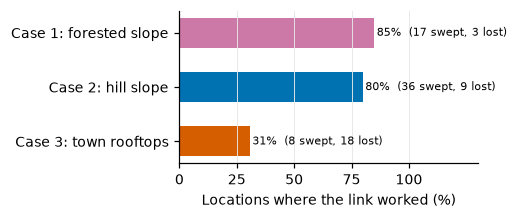

In [13]:
def hav(la1, lo1, la2, lo2):
    R = 6371000; p1, p2 = np.radians(la1), np.radians(la2)
    a = np.sin((p2 - p1) / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(np.radians(lo2 - lo1) / 2) ** 2
    return 2 * R * np.arcsin(np.sqrt(a))
st = stations.set_index('site')
fails['dist_m'] = hav(st.loc[fails.site, 'station_lat'].values, st.loc[fails.site, 'station_lon'].values, fails.lat, fails.lon)
fails['nearest_sweep_m'] = [hav(r.lat, r.lon, s[s.site == r.site].lat.values, s[s.site == r.site].lon.values).min() for r in fails.itertuples()]
far = fails[fails.nearest_sweep_m > 30]; keep = []
for r in far.itertuples():
    if not any(k.site == r.site and hav(r.lat, r.lon, k.lat, k.lon) < 30 for k in keep): keep.append(r)
lost = pd.DataFrame(keep); lost['case'] = lost.site.map(CASE)
print('failed attempts:', len(fails), '| unique lost locations:', len(lost))

swept = s.groupby('case').size(); lc_ = lost.groupby('case').size(); succ = 100 * swept / (swept + lc_)
print(pd.DataFrame({'swept': swept, 'lost': lc_, 'link_success_%': succ.round(0)}))
both = pd.concat([pd.DataFrame({'d': s.distance_to_station_m, 'link': 1}), pd.DataFrame({'d': lost.dist_m, 'link': 0})])
both['band'] = pd.cut(both.d, [0, 300, 1000, 2000, 4000], labels=['<=300 m', '0.3-1 km', '1-2 km', '2-4 km'])
print(both.groupby('band', observed=True).link.agg(swept='sum', locations='count', success_pct=lambda v: round(100 * v.mean())))
RESULTS.update(lost=len(lost), link_c3=succ[3])

fig, ax = plt.subplots(figsize=(W, 1.8))
ax.barh(range(3), [succ[c] for c in (1, 2, 3)], .55, color=[COL[c] for c in (1, 2, 3)])
for i, c in enumerate((1, 2, 3)): ax.text(succ[c] + 1, i, f'{succ[c]:.0f}%  ({swept[c]} swept, {lc_[c]} lost)', va='center', fontsize=7)
ax.set_yticks(range(3)); ax.set_yticklabels([NAME[c] for c in (1, 2, 3)]); ax.invert_yaxis(); ax.set_xlim(0, 130); ax.set_xticks([0, 25, 50, 75, 100])
ax.set_xlabel('Locations where the link worked (%)'); ax.grid(axis='y', visible=False)
fig.savefig(f'{FIG}/fig8_link_success_by_case.png'); plt.show()

In [14]:
from scipy.stats import kruskal

prof = {}
for c in (1, 2, 3):
    d = s[s.case == c]; pc = p[p.case == c]
    prof[f'Case {c}'] = {'stops': len(d), 'distance median (m)': d.distance_to_station_m.median(),
        'distance range (m)': f'{d.distance_to_station_m.min():.0f}-{d.distance_to_station_m.max():.0f}',
        'elev diff range (m)': f'{d.elev_diff_m.min():.0f} to {d.elev_diff_m.max():.0f}',
        'received / slots': f'{pc.ok.sum()}/{len(pc)}', 'delivery %': round(100 * pc.ok.mean(), 1),
        'median stop delivery %': round(100 * d.delivery_rate.median(), 1),
        'median PL14 (dB)': d.pl_median_14dbm.median(),
        'PL14 IQR (dB)': f'{d.pl_median_14dbm.quantile(.25):.1f}-{d.pl_median_14dbm.quantile(.75):.1f}'}
print(pd.DataFrame(prof).to_string())
kw_d = kruskal(*[g.delivery_rate for _, g in s.groupby('case')]); kw_p = kruskal(*[g.pl_median_14dbm.dropna() for _, g in s.groupby('case')])
print(f'\nKruskal-Wallis: delivery p = {kw_d.pvalue:.2f} | median path loss p = {kw_p.pvalue:.2f}  -> not significant')
RESULTS.update(kw_delivery=kw_d.pvalue, kw_pl=kw_p.pvalue)

                             Case 1       Case 2       Case 3
stops                            17           36            8
distance median (m)           185.0       1373.5       2247.5
distance range (m)           22-250     209-2916     272-3268
elev diff range (m)         0 to 36   -34 to 113    -4 to 287
received / slots           563/1530    1737/3240      312/720
delivery %                     36.8         53.6         43.3
median stop delivery %         35.6         52.8         46.1
median PL14 (dB)              129.5        130.0        134.0
PL14 IQR (dB)           124.0-135.5  118.6-137.0  130.8-138.6

Kruskal-Wallis: delivery p = 0.18 | median path loss p = 0.34  -> not significant


## 8. Path loss regression

                   model  LOO  LOCO  LOCO case1  LOCO case2  LOCO case3
               Mean only 11.1  11.4         8.4        12.9         9.1
            Log-distance 11.3  13.0         9.8        14.8         9.5
 + elev. diff. and angle 11.4  15.8        11.2        16.3        20.9
    + land cover (ridge) 11.1  15.7         8.4        17.1        19.8
Regression tree, depth 3 11.2  15.3         9.5        16.9        16.8

Within one case (LOO inside the case):
  Case 1 (16 stops): mean 8.7 | log-distance 8.0 | + elevation diff 7.2
  Case 2 (36 stops): mean 12.6 | log-distance 12.9 | + elevation diff 11.9
Strict subset (>=10 received, 51 stops): mean 10.6 | log-distance 10.9
Manual line-of-sight check, delivery %: {'blocked': 27.0, 'clear': 76.0, 'partly blocked': 53.0}


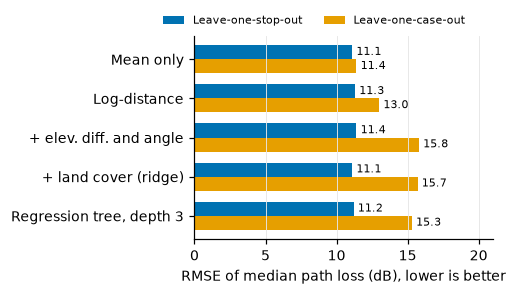

In [15]:
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import LeaveOneOut, LeaveOneGroupOut, cross_val_predict

y = d60.pl_median_14dbm.values; g = d60.case.values
MODELS = {
  'Mean only':                   (LinearRegression(), None),
  'Log-distance':                (LinearRegression(), ['logd']),
  '+ elev. diff. and angle':     (LinearRegression(), ['logd', 'elev_diff_m', 'elev_angle_deg']),
  '+ land cover (ridge)':        (make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 30))), ['logd', 'elev_diff_m', 'elev_angle_deg'] + LC),
  'Regression tree, depth 3':    (DecisionTreeRegressor(max_depth=3, min_samples_leaf=5, random_state=0), ['logd', 'elev_diff_m', 'elev_angle_deg'] + LC)}
rows = []
for name, (m, cols) in MODELS.items():
    X = np.zeros((len(y), 1)) if cols is None else d60[cols].values
    loo = cross_val_predict(m, X, y, cv=LeaveOneOut()); lc = cross_val_predict(m, X, y, groups=g, cv=LeaveOneGroupOut())
    rows.append([name, rmse(y, loo), rmse(y, lc)] + [rmse(y[g == c], lc[g == c]) for c in (1, 2, 3)])
reg = pd.DataFrame(rows, columns=['model', 'LOO', 'LOCO', 'LOCO case1', 'LOCO case2', 'LOCO case3']).round(1)
print(reg.to_string(index=False)); RESULTS.update(rmse_mean=reg.LOO[0], rmse_logd_loco=reg.LOCO[1], rmse_terrain_loco=reg.LOCO[2])

print('\nWithin one case (LOO inside the case):')
for c in (1, 2):
    dd = d60[d60.case == c]; yy = dd.pl_median_14dbm.values
    r = [rmse(yy, cross_val_predict(LinearRegression(), X_, yy, cv=LeaveOneOut())) for X_ in [np.zeros((len(yy), 1)), dd[['logd']], dd[['logd', 'elev_diff_m']]]]
    print(f'  Case {c} ({len(dd)} stops): mean {r[0]:.1f} | log-distance {r[1]:.1f} | + elevation diff {r[2]:.1f}')
d51 = d60[d60.n_ok >= 10]; y51 = d51.pl_median_14dbm.values
print('Strict subset (>=10 received, %d stops): mean %.1f | log-distance %.1f' % (len(d51),
      rmse(y51, cross_val_predict(LinearRegression(), np.zeros((len(y51), 1)), y51, cv=LeaveOneOut())),
      rmse(y51, cross_val_predict(LinearRegression(), d51[['logd']], y51, cv=LeaveOneOut()))))
print('Manual line-of-sight check, delivery %:', (s.groupby('line_of_sight').delivery_rate.mean() * 100).round(0).to_dict())

fig, ax = plt.subplots(figsize=(W, 2.4)); h = .36; yy_ = np.arange(len(reg))
ax.barh(yy_ - h/2, reg.LOO, h, color='#0072B2', label='Leave-one-stop-out'); ax.barh(yy_ + h/2, reg.LOCO, h, color='#E69F00', label='Leave-one-case-out')
for i, r in reg.iterrows():
    ax.text(r.LOO + .3, i - h/2, f'{r.LOO:.1f}', va='center', fontsize=7); ax.text(r.LOCO + .3, i + h/2, f'{r.LOCO:.1f}', va='center', fontsize=7)
ax.set_yticks(yy_); ax.set_yticklabels(reg.model); ax.invert_yaxis(); ax.set_xlim(0, 21)
ax.set_xlabel('RMSE of median path loss (dB), lower is better'); ax.grid(axis='y', visible=False)
ax.legend(fontsize=7, frameon=False, loc='lower center', bbox_to_anchor=(.4, 1.0), ncol=2)
fig.savefig(f'{FIG}/fig4_regression_rmse.png'); plt.show()

## 9. Delivery classification
### Decision trees

majority-class plain accuracy: 0.524
                  model  bal_acc   AUC  LOCO_bal_acc  LOCO_case1  LOCO_case2  LOCO_case3
         Majority class    0.500 0.500           NaN         NaN         NaN         NaN
       Link-budget rule    0.538 0.727           NaN         NaN         NaN         NaN
             SF + power    0.679 0.713         0.671       0.689       0.672       0.716
             + distance    0.684 0.698         0.628       0.659       0.638       0.568
+ elev. diff. and angle    0.620 0.645         0.501       0.500       0.573       0.559
           + land cover    0.620 0.641         0.501       0.500       0.573       0.559


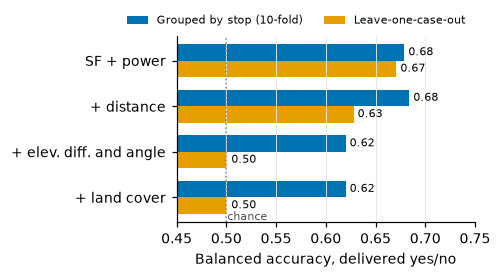

In [16]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GroupKFold
from sklearn.metrics import balanced_accuracy_score, roc_auc_score

yp = p.ok.values; GS = p.stop_key.values; GC = p.case.values; gkf = GroupKFold(n_splits=10)
SENS = {7: -124.5, 8: -127, 9: -129.5, 10: -132, 11: -134.5, 12: -137}
pred = np.zeros(len(p)); prob = np.zeros(len(p))
for tr, te in gkf.split(p, yp, GS):
    trp = p.iloc[tr]; trs = trp[trp.pwr == 14].groupby('stop_key').agg(pl=('pl_db', 'median'), logd=('logd', 'first')).dropna()
    b = np.polyfit(trs.logd, trs.pl, 1); te_ = p.iloc[te]
    margin = te_.pwr - np.polyval(b, te_.logd) - te_.sf.map(SENS)
    pred[te] = (margin > 0).astype(int); prob[te] = 1 / (1 + np.exp(-margin / 3))
rows = [['Majority class', .5, .5, np.nan, np.nan, np.nan, np.nan],
        ['Link-budget rule', balanced_accuracy_score(yp, pred), roc_auc_score(yp, prob), np.nan, np.nan, np.nan, np.nan]]
SETS = {'SF + power': ['sf', 'pwr'], '+ distance': ['sf', 'pwr', 'logd'],
        '+ elev. diff. and angle': ['sf', 'pwr', 'logd', 'elev_diff_m', 'elev_angle_deg'],
        '+ land cover': ['sf', 'pwr', 'logd', 'elev_diff_m', 'elev_angle_deg'] + LC}
for name, cols in SETS.items():
    tree = DecisionTreeClassifier(max_depth=3, min_samples_leaf=90, random_state=0)
    a = cross_val_predict(tree, p[cols], yp, groups=GS, cv=gkf, method='predict_proba')[:, 1]
    b_ = cross_val_predict(tree, p[cols], yp, groups=GC, cv=LeaveOneGroupOut(), method='predict_proba')[:, 1]
    rows.append([name, balanced_accuracy_score(yp, a > .5), roc_auc_score(yp, a), balanced_accuracy_score(yp, b_ > .5)]
                + [balanced_accuracy_score(yp[GC == c], b_[GC == c] > .5) for c in (1, 2, 3)])
clf = pd.DataFrame(rows, columns=['model', 'bal_acc', 'AUC', 'LOCO_bal_acc', 'LOCO_case1', 'LOCO_case2', 'LOCO_case3']).round(3)
print('majority-class plain accuracy: %.3f' % max(yp.mean(), 1 - yp.mean())); print(clf.to_string(index=False))
RESULTS.update(tree_sfpwr=clf.bal_acc[2], tree_sfpwr_loco=clf.LOCO_bal_acc[2], tree_full_loco=clf.LOCO_bal_acc[5], linkbudget_auc=clf.AUC[1])

c2 = clf.iloc[2:].reset_index(drop=True); fig, ax = plt.subplots(figsize=(W, 2.2)); h = .36; yy_ = np.arange(len(c2))
ax.barh(yy_ - h/2, c2.bal_acc, h, color='#0072B2', label='Grouped by stop (10-fold)'); ax.barh(yy_ + h/2, c2.LOCO_bal_acc, h, color='#E69F00', label='Leave-one-case-out')
for i, r in c2.iterrows():
    ax.text(r.bal_acc + .004, i - h/2, f'{r.bal_acc:.2f}', va='center', fontsize=7); ax.text(r.LOCO_bal_acc + .004, i + h/2, f'{r.LOCO_bal_acc:.2f}', va='center', fontsize=7)
ax.axvline(.5, c='#888', ls=':', lw=1); ax.text(.501, len(c2) - .5, 'chance', fontsize=7, color='#555')
ax.set_xlim(.45, .75); ax.set_yticks(yy_); ax.set_yticklabels(c2.model); ax.invert_yaxis(); ax.set_xlabel('Balanced accuracy, delivered yes/no'); ax.grid(axis='y', visible=False)
ax.legend(fontsize=7, frameon=False, loc='lower center', bbox_to_anchor=(.4, 1.0), ncol=2)
fig.savefig(f'{FIG}/fig5_classifier_balacc.png'); plt.show()

|--- pwr <= 11.00
|   |--- elev_diff_m <= 57.00
|   |   |--- sf <= 10.50
|   |   |   |--- weights: [1387.00, 373.00] class: 0
|   |   |--- sf >  10.50
|   |   |   |--- weights: [486.00, 394.00] class: 0
|   |--- elev_diff_m >  57.00
|   |   |--- logd <= 3.35
|   |   |   |--- weights: [267.00, 513.00] class: 1
|   |   |--- logd >  3.35
|   |   |   |--- weights: [172.00, 68.00] class: 0
|--- pwr >  11.00
|   |--- sf <= 10.50
|   |   |--- elev_diff_m <= 48.00
|   |   |   |--- weights: [371.00, 409.00] class: 1
|   |   |--- elev_diff_m >  48.00
|   |   |   |--- weights: [103.00, 337.00] class: 1
|   |--- sf >  10.50
|   |   |--- elev_angle_deg <= 8.48
|   |   |   |--- weights: [59.00, 451.00] class: 1
|   |   |--- elev_angle_deg >  8.48
|   |   |   |--- weights: [33.00, 67.00] class: 1



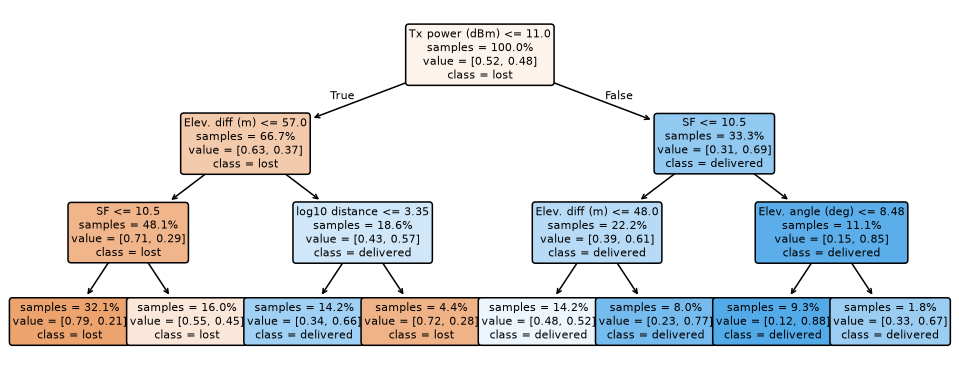

 training stops  bal_acc mean    sd
              9         0.565 0.084
             19         0.596 0.077
             29         0.606 0.074
             39         0.638 0.059
             49         0.621 0.039


In [17]:
from sklearn.tree import plot_tree, export_text

cols = SETS['+ land cover']
tree = DecisionTreeClassifier(max_depth=3, min_samples_leaf=90, random_state=0).fit(p[cols], yp)
print(export_text(tree, feature_names=cols, show_weights=True))
names = ['SF', 'Tx power (dBm)', 'log10 distance', 'Elev. diff (m)', 'Elev. angle (deg)', 'LC built-up', 'LC mixed', 'LC open']
fig, ax = plt.subplots(figsize=(11, 4.2))
plot_tree(tree, feature_names=names, class_names=['lost', 'delivered'], filled=True, impurity=False, proportion=True, rounded=True, fontsize=7, precision=2, ax=ax)
fig.savefig(f'{FIG}/fig6_tree_depth3.png'); plt.show()

stops_ = p.stop_key.unique(); rng = np.random.default_rng(1); lc_rows = []
for frac in [.2, .4, .6, .8, 1.0]:
    accs = []
    for _ in range(30):
        test = rng.choice(stops_, int(.2 * len(stops_)), replace=False); pool = np.setdiff1d(stops_, test)
        trn = rng.choice(pool, max(3, int(frac * len(pool))), replace=False)
        m = DecisionTreeClassifier(max_depth=3, min_samples_leaf=90, random_state=0).fit(p[p.stop_key.isin(trn)][cols], p[p.stop_key.isin(trn)].ok)
        te = p[p.stop_key.isin(test)]; accs.append(balanced_accuracy_score(te.ok, m.predict(te[cols])))
    lc_rows.append((int(frac * len(pool)), np.mean(accs), np.std(accs)))
print(pd.DataFrame(lc_rows, columns=['training stops', 'bal_acc mean', 'sd']).round(3).to_string(index=False))

### Random forest

In [18]:
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.model_selection import KFold

full = SETS['+ land cover']
rf = RandomForestClassifier(300, random_state=0, n_jobs=-1)
r_rand = cross_val_predict(rf, p[full], yp, cv=KFold(10, shuffle=True, random_state=0), method='predict_proba')[:, 1]
r_grp  = cross_val_predict(rf, p[full], yp, groups=GS, cv=gkf, method='predict_proba')[:, 1]
r_case = cross_val_predict(rf, p[full], yp, groups=GC, cv=LeaveOneGroupOut(), method='predict_proba')[:, 1]
print('Random forest (delivery) balanced accuracy:  random split %.2f  | grouped by stop %.2f (AUC %.2f) | new case %.2f'
      % (balanced_accuracy_score(yp, r_rand > .5), balanced_accuracy_score(yp, r_grp > .5), roc_auc_score(yp, r_grp), balanced_accuracy_score(yp, r_case > .5)))
RESULTS.update(rf_random=balanced_accuracy_score(yp, r_rand > .5), rf_grouped=balanced_accuracy_score(yp, r_grp > .5), rf_loco=balanced_accuracy_score(yp, r_case > .5))
rfr = RandomForestRegressor(300, random_state=0, n_jobs=-1); cols_r = ['logd', 'elev_diff_m', 'elev_angle_deg'] + LC
loo = cross_val_predict(rfr, d60[cols_r], y, cv=LeaveOneOut()); lc = cross_val_predict(rfr, d60[cols_r], y, groups=g, cv=LeaveOneGroupOut())
print('Random forest (path loss) RMSE: LOO %.1f | LOCO %.1f   (mean-only: 11.1 / 11.4)' % (rmse(y, loo), rmse(y, lc)))
RESULTS.update(rf_pl_loo=rmse(y, loo), rf_pl_loco=rmse(y, lc))

Random forest (delivery) balanced accuracy:  random split 0.89  | grouped by stop 0.65 (AUC 0.71) | new case 0.55
Random forest (path loss) RMSE: LOO 11.3 | LOCO 15.0   (mean-only: 11.1 / 11.4)


### Other models, metrics, ROC and confusion matrix

                            model  bal_acc  precision  recall    F1   AUC    AP  LOCO_bal_acc   TN   FP   FN   TP
                 Link-budget rule    0.538      0.496   0.970 0.656 0.727 0.706           NaN  302 2576   78 2534
                 Tree, SF + power    0.679      0.699   0.587 0.638 0.713 0.684         0.671 2217  661 1078 1534
               Tree, all features    0.620      0.625   0.528 0.573 0.641 0.600         0.501 2052  826 1233 1379
      Random forest, all features    0.646      0.633   0.618 0.625 0.707 0.664         0.553 1942  936  998 1614
  Logistic regression, SF + power    0.677      0.672   0.637 0.654 0.734 0.706         0.654 2066  812  949 1663
Logistic regression, all features    0.674      0.664   0.644 0.654 0.726 0.697         0.556 2026  852  929 1683
  Gradient boosting, all features    0.680      0.661   0.674 0.667 0.745 0.723         0.576 1974  904  851 1761


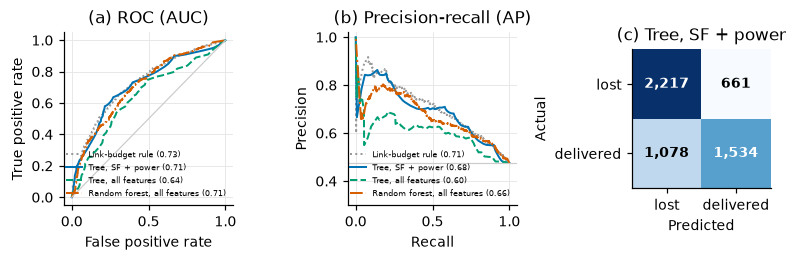

In [19]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (precision_score, recall_score, f1_score, confusion_matrix, roc_curve,
                             precision_recall_curve, average_precision_score)
SFP, ALLF = SETS['SF + power'], SETS['+ land cover']
mk_tree = lambda: DecisionTreeClassifier(max_depth=3, min_samples_leaf=90, random_state=0)
MODELS = {'Tree, SF + power': (mk_tree(), SFP), 'Tree, all features': (mk_tree(), ALLF),
          'Random forest, all features': (RandomForestClassifier(300, random_state=0, n_jobs=-1), ALLF),
          'Logistic regression, SF + power': (make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)), SFP),
          'Logistic regression, all features': (make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)), ALLF),
          'Gradient boosting, all features': (HistGradientBoostingClassifier(random_state=0), ALLF)}
PROBS = {'Link-budget rule': prob}; LOCO = {'Link-budget rule': np.nan}
for name, (mdl, cols) in MODELS.items():
    PROBS[name] = cross_val_predict(mdl, p[cols], yp, groups=GS, cv=gkf, method='predict_proba')[:, 1]
    LOCO[name] = balanced_accuracy_score(yp, cross_val_predict(mdl, p[cols], yp, groups=GC, cv=LeaveOneGroupOut(), method='predict_proba')[:, 1] > .5)
rows = []
for name, pr in PROBS.items():
    yhat = (pred > 0) if name == 'Link-budget rule' else (pr > .5)
    tn, fp, fn, tp = confusion_matrix(yp, yhat).ravel()
    rows.append([name, balanced_accuracy_score(yp, yhat), precision_score(yp, yhat), recall_score(yp, yhat), f1_score(yp, yhat),
                 roc_auc_score(yp, pr), average_precision_score(yp, pr), LOCO[name], tn, fp, fn, tp])
full = pd.DataFrame(rows, columns=['model', 'bal_acc', 'precision', 'recall', 'F1', 'AUC', 'AP', 'LOCO_bal_acc', 'TN', 'FP', 'FN', 'TP'])
print(full.round(3).to_string(index=False))
RESULTS.update(tree_precision=full.precision[1], tree_recall=full.recall[1], tree_f1=full.F1[1], gb_auc=full.AUC[6], gb_loco=full.LOCO_bal_acc[6],
               lr_sfp_loco=full.LOCO_bal_acc[4], linkbudget_recall=full.recall[0])

fig, ax = plt.subplots(1, 3, figsize=(W * 2.05, 2.45), gridspec_kw=dict(width_ratios=[1, 1, .82]))
for n, c, ls in [('Link-budget rule', '#999999', ':'), ('Tree, SF + power', '#0072B2', '-'),
                 ('Tree, all features', '#009E73', '--'), ('Random forest, all features', '#D55E00', '-.')]:
    fpr, tpr, _ = roc_curve(yp, PROBS[n]); ax[0].plot(fpr, tpr, c=c, ls=ls, lw=1.3, label=f'{n} ({roc_auc_score(yp, PROBS[n]):.2f})')
    pr_, rc_, _ = precision_recall_curve(yp, PROBS[n]); ax[1].plot(rc_, pr_, c=c, ls=ls, lw=1.3, label=f'{n} ({average_precision_score(yp, PROBS[n]):.2f})')
ax[0].plot([0, 1], [0, 1], c='#ccc', lw=.8); ax[0].set(xlabel='False positive rate', ylabel='True positive rate', title='(a) ROC (AUC)')
ax[1].axhline(yp.mean(), c='#ccc', lw=.8); ax[1].set(xlabel='Recall', ylabel='Precision', title='(b) Precision-recall (AP)', ylim=(.3, 1.02))
for a in ax[:2]: a.legend(fontsize=5.2, frameon=False, loc='lower right')
cm = confusion_matrix(yp, PROBS['Tree, SF + power'] > .5); ax[2].imshow(cm, cmap='Blues'); ax[2].grid(False)
for i in range(2):
    for j in range(2): ax[2].text(j, i, f'{cm[i, j]:,}', ha='center', va='center', fontweight='bold', color='white' if cm[i, j] > 1500 else 'black')
ax[2].set_xticks([0, 1], ['lost', 'delivered']); ax[2].set_yticks([0, 1], ['lost', 'delivered']); ax[2].set(xlabel='Predicted', ylabel='Actual', title='(c) Tree, SF + power')
fig.tight_layout(); fig.savefig(f'{FIG}/fig9_roc_pr_cm.png'); plt.show()

## 10. Cheapest setting per stop

In [20]:
mw = {2: 10 ** .2, 8: 10 ** .8, 14: 10 ** 1.4}
gs = p.groupby(['stop_key', 'case', 'sf', 'pwr']).ok.sum().reset_index()
gs['cost'] = 2.0 ** (gs.sf - 7) * gs.pwr.map(mw)
best = gs[gs.ok >= 4].sort_values('cost').groupby('stop_key').first()
ms = p.groupby('stop_key').case.first().to_frame().join(best[['sf', 'pwr', 'cost']])
full_cost = 32 * mw[14]
rows = []
for c, dd in list(ms.groupby('case')) + [('All', ms)]:
    sv = dd[dd.sf.notna()]
    rows.append([c, f'{len(sv)}/{len(dd)}', int(((sv.sf <= 9) & (sv.pwr <= 8)).sum()), int(((sv.sf >= 11) & (sv.pwr == 14)).sum()),
                 round(100 * (1 - sv.cost / full_cost).median())])
mt = pd.DataFrame(rows, columns=['case', 'stops with a working setting', 'low cost (SF<=9, <=8 dBm)', 'needed SF11-12 at 14 dBm', 'median energy saving %'])
print(mt.to_string(index=False))
RESULTS.update(min_served=int(ms.sf.notna().sum()), min_saving=float(mt.iloc[-1, -1]))

case stops with a working setting  low cost (SF<=9, <=8 dBm)  needed SF11-12 at 14 dBm  median energy saving %
   1                        13/17                          4                         2                      97
   2                        34/36                         13                         3                      97
   3                          8/8                          2                         2                      92
 All                        55/61                         19                         7                      97


## 11. Computational cost

In [21]:
import time, pickle

cols_r = ['logd', 'elev_diff_m', 'elev_angle_deg'] + LC
def cost(name, mdl, X, y_):
    ft = []; pt = []
    for _ in range(5):
        t0 = time.perf_counter(); mdl.fit(X, y_); ft.append(time.perf_counter() - t0)
        t0 = time.perf_counter(); mdl.predict(X); pt.append(time.perf_counter() - t0)
    return dict(model=name, fit_ms=1e3 * np.median(ft), predict_us_per_sample=1e6 * np.median(pt) / len(X), size_kB=len(pickle.dumps(mdl)) / 1024)
cc = pd.DataFrame([
    cost('Log-distance (OLS)', LinearRegression(), d60[['logd']], d60.pl_median_14dbm),
    cost('Ridge, all features', make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 30))), d60[cols_r], d60.pl_median_14dbm),
    cost('Regression tree, depth 3', DecisionTreeRegressor(max_depth=3, min_samples_leaf=5, random_state=0), d60[cols_r], d60.pl_median_14dbm),
    cost('RF regressor, 300 trees', RandomForestRegressor(300, random_state=0, n_jobs=1), d60[cols_r], d60.pl_median_14dbm),
    cost('Tree, SF + power', mk_tree(), p[SFP], yp), cost('Tree, all features', mk_tree(), p[ALLF], yp),
    cost('RF classifier, 300 trees', RandomForestClassifier(300, random_state=0, n_jobs=1), p[ALLF], yp)]).round(2)
print(cc.to_string(index=False))
print('RF classifier is %.0fx larger than the SF + power tree' % (cc.size_kB.iloc[-1] / cc.size_kB.iloc[4]))

                   model  fit_ms  predict_us_per_sample  size_kB
      Log-distance (OLS)    1.32                   9.68     0.59
     Ridge, all features    4.16                  13.92     1.42
Regression tree, depth 3    1.24                   9.72     1.83
 RF regressor, 300 trees  282.25                 431.54  1574.60
        Tree, SF + power    1.84                   0.13     2.40
      Tree, all features    2.97                   0.14     2.47
RF classifier, 300 trees  885.72                  14.62 24397.74
RF classifier is 10166x larger than the SF + power tree


## 12. Conclusion
- RQ1: no path loss model beat the mean (RMSE 11.1 dB).
- RQ2: the SF + power tree transferred to an unseen case (0.67); terrain features did not.
- RQ3: 55 of 61 stops had a working setting, with a median 97% energy saving.